# Two-Tunable Qubit Hamiltonian

Model and plumbing live in `two_qubit_model.py`; this notebook sets parameters, builds control pulses and rolls out the dynamics.

**Frame:** rotating at each qubit's idle frequency, RWA.

$$\frac{H(t)}{2\pi} = \sum_i \Big[\Delta_i(t)\, n_i + \tfrac{\alpha_i}{2} b_i^{\dagger 2} b_i^2 + \tfrac{u_{x,i}}{2}(b_i + b_i^\dagger) + \tfrac{u_{y,i}}{2}\, i(b_i^\dagger - b_i)\Big] + J\big(e^{i\delta t} b_1^\dagger b_2 + \text{h.c.}\big)$$

* $\Delta_i(t) = f_i(I(t)) - f_{\text{idle},i}$, with $f_i(\Phi) = f_{\max,i}\sqrt{|\cos(\pi\Phi_i/\Phi_0)|}$ and $\Phi_i = \sum_j M_{ij} I_j$ (crosstalk included).
* $\delta = 2\pi(f_{\text{idle},1} - f_{\text{idle},2})$: the coupling only acts efficiently when flux brings the qubits into resonance.
* `n_levels=2` gives the Pauli model; `n_levels=3` adds leakage.

**Units:** ns, GHz (cyclic), mA, pH. **Controls** are piecewise constant on `N` slices of width `dt`: `I`, `ux`, `uy` each have shape `(2, N)`.

In [2]:
import numpy as np
import qutip as qt
import matplotlib.pyplot as plt

from two_qubit_model import QubitParams, SystemParams, Controls, TwoQubitModel

## System parameters

In [3]:
params = SystemParams(
    q1=QubitParams(f_max=6.0, alpha=-0.20),   # GHz
    q2=QubitParams(f_max=5.6, alpha=-0.21),
    J=0.010,                                  # GHz (10 MHz)
    M=[[2.00, 0.05],                          # pH, M[i, j]: flux line j -> SQUID i
       [0.05, 2.00]],
    I_idle=[0.0, 0.0],                        # mA (both parked at the sweet spot)
    n_levels=3,
)
model = TwoQubitModel(params)
print("idle frequencies [GHz]:", model.f_idle)
print("idle detuning delta/2pi [GHz]:", model.delta / (2 * np.pi))

idle frequencies [GHz]: [6.  5.6]
idle detuning delta/2pi [GHz]: 0.40000000000000036


## Example control pulses
A Gaussian X π pulse on qubit 1 (|00⟩ → |10⟩), then a flux pulse that tunes qubit 1 into resonance with qubit 2 for $1/(4J)$ (|10⟩ → |01⟩).
Replace these arrays with your optimizer's output.

resonance currents [mA]: [ 0.16904759 -0.00422619]


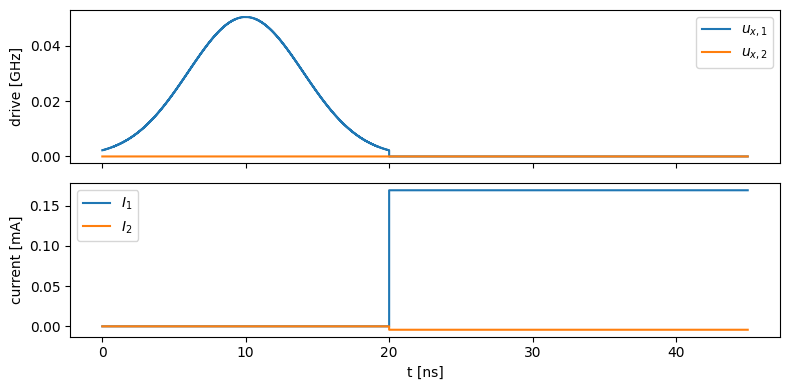

In [4]:
dt = 0.02                                  # ns per slice
t_pi, t_swap = 20.0, 1 / (4 * params.J)    # ns
N_pi, N_swap = round(t_pi / dt), round(t_swap / dt)
N = N_pi + N_swap

ctrl = Controls.idle(model, N, dt)          # flux at idle, drives off

# Gaussian pi pulse on qubit 1, normalized so the area gives exactly a pi rotation
t = ctrl.t_mid[:N_pi]
g = np.exp(-0.5 * ((t - t_pi / 2) / (t_pi / 5)) ** 2)
ctrl.ux[0, :N_pi] = 0.5 * g / (g.sum() * dt)

# Flux pulse: currents that put qubit 1 at qubit 2's idle frequency (crosstalk-corrected)
I_res = model.currents_for_frequencies([model.f_idle[1], model.f_idle[1]])
ctrl.I[:, N_pi:] = I_res[:, None]
print("resonance currents [mA]:", I_res)

fig, ax = plt.subplots(2, 1, sharex=True, figsize=(8, 4))
for i in range(2):
    ax[0].step(ctrl.t_mid, ctrl.ux[i], where="mid", label=f"$u_{{x,{i+1}}}$")
    ax[1].step(ctrl.t_mid, ctrl.I[i], where="mid", label=f"$I_{i+1}$")
ax[0].set_ylabel("drive [GHz]"); ax[1].set_ylabel("current [mA]"); ax[1].set_xlabel("t [ns]")
ax[0].legend(); ax[1].legend(); plt.tight_layout()

## Rollout

{'00': 0.01273, '01': 0.9866, '10': 0.00062, '11': 0.0, 'leak': 5e-05}


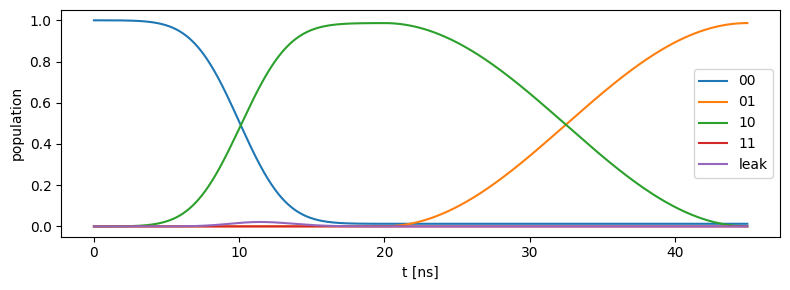

In [5]:
labels = ["00", "01", "10", "11", "leak"]
P = [model.basis(0, 0).proj(), model.basis(0, 1).proj(), model.basis(1, 0).proj(), model.basis(1, 1).proj()]
P.append(qt.qeye(model.dims) - sum(P))

# Closed system. Pass c_ops=model.collapse_ops(T1=(30e3, 30e3), Tphi=(40e3, 40e3)) for decoherence.
res = model.evolve(ctrl, model.basis(0, 0), e_ops=P)

plt.figure(figsize=(8, 3))
for lab, p in zip(labels, res.expect):
    plt.plot(res.times, p, label=lab)
plt.xlabel("t [ns]"); plt.ylabel("population"); plt.legend(); plt.tight_layout()
print({lab: round(float(p[-1]), 5) for lab, p in zip(labels, res.expect)})

# Online "Hardware" Model
Our mutual inductance is SHITTT

{'00': 0.01273, '01': 0.05388, '10': 0.93334, '11': 0.0, 'leak': 5e-05}


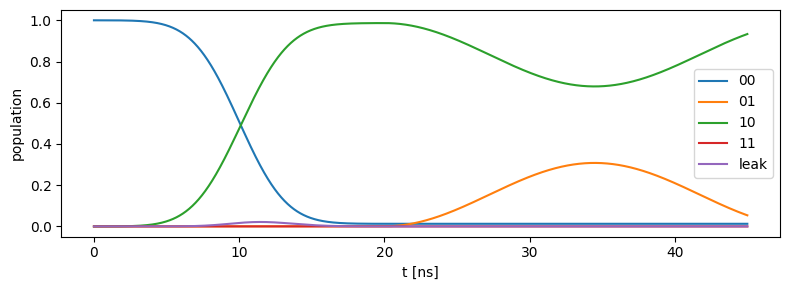

In [8]:
real_params = SystemParams(
    q1=QubitParams(f_max=6.0, alpha=-0.20),   # GHz
    q2=QubitParams(f_max=5.6, alpha=-0.21),
    J=0.010,                                  # GHz (10 MHz)
    M=[[2.00, 0.55],                          # pH, M[i, j]: flux line j -> SQUID i
       [0.55, 2.00]],                         # This is SHITTTTT
    I_idle=[0.0, 0.0],                        # mA (both parked at the sweet spot)
    n_levels=3,
)
real_model = TwoQubitModel(real_params)

labels = ["00", "01", "10", "11", "leak"]
P = [real_model.basis(0, 0).proj(), real_model.basis(0, 1).proj(), real_model.basis(1, 0).proj(), real_model.basis(1, 1).proj()]
P.append(qt.qeye(real_model.dims) - sum(P))


# Closed system. Pass c_ops=real_model.collapse_ops(T1=(30e3, 30e3), Tphi=(40e3, 40e3)) for decoherence.
real_res = real_model.evolve(ctrl, real_model.basis(0, 0), e_ops=P)

plt.figure(figsize=(8, 3))
for lab, p in zip(labels, real_res.expect):
    plt.plot(real_res.times, p, label=lab)
plt.xlabel("t [ns]"); plt.ylabel("population"); plt.legend(); plt.tight_layout()
print({lab: round(float(p[-1]), 5) for lab, p in zip(labels, real_res.expect)})

## SVD-ILC
Nominal pulse `ctrl` in the offline `model` (crosstalk 0.05); "hardware" = `real_model` (crosstalk 0.55) with shot noise.

1. Analytic Jacobian $J = \partial y(t_k)/\partial a_m(t_n)$ of the offline model, stacked over checkpoint times, input states and Pauli observables.
2. Rank-4 SVD $J \approx U_r \Sigma_r V_r^\top$: $V_r$ = pulse-correction modes, $U_r$ = error modes.
3. Pick 4 measurement times from $U_r$ (greedy D-optimal / max Fisher information).
4. ILC: measure hardware at those 4 times only, fit the 4 mode coefficients, $a \leftarrow a - g\,V_r c$.

J: (1080, 13500)  Sigma_r: [30.342 13.567  5.823  3.883]
measurement times [ns]: [23.5 28.5 34.  42.5]


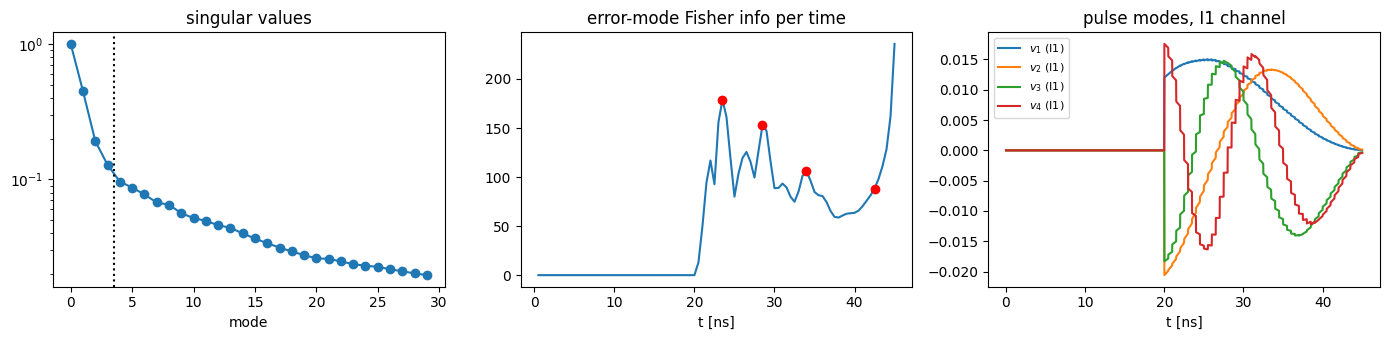

In [9]:
from ilc import SVDILC, embedded_paulis, product_state, tracking_fidelity

paulis = embedded_paulis(model)                                   # XI, IX, YI, IY, ZI, IZ
states = [product_state(model, "0", "0"), product_state(model, "+", "+")]
checkpoints = np.arange(25, ctrl.n_slices + 1, 25)                # candidate times every 0.5 ns

ilc = SVDILC(model, states, list(paulis.values()), checkpoints)
J, y_nom = ilc.compute_jacobian(ctrl)
V_r, U_r, Sigma_r = ilc.compute_svd_basis(J, r_rank=4)

SHOTS = 1000
meas_pos, score = ilc.select_measurement_times(U_r, n_times=4, y_nom=y_nom, shots=SHOTS)
meas_rows = ilc.rows_for_times(meas_pos)
t_ck = checkpoints * ctrl.dt
print("J:", J.shape, " Sigma_r:", np.round(Sigma_r, 3))
print("measurement times [ns]:", t_ck[meas_pos])

fig, ax = plt.subplots(1, 3, figsize=(14, 3.5))
S_all = np.linalg.svd(J, compute_uv=False)
ax[0].semilogy(S_all[:30] / S_all[0], "o-"); ax[0].axvline(3.5, color="k", ls=":")
ax[0].set_title("singular values"); ax[0].set_xlabel("mode")
ax[1].plot(t_ck, score); ax[1].plot(t_ck[meas_pos], score[meas_pos], "ro")
ax[1].set_title("error-mode Fisher info per time"); ax[1].set_xlabel("t [ns]")
modes = V_r.T.reshape(4, 6, -1) * ilc.scales[None, :, None]
for i in range(4):
    ax[2].plot(ctrl.t_mid, modes[i, 0], label=f"$v_{i+1}$ (I1)")
ax[2].set_title("pulse modes, I1 channel"); ax[2].set_xlabel("t [ns]"); ax[2].legend(fontsize=8)
plt.tight_layout()

iter 0: rms trajectory error 0.3998   tracking fidelity 0.03936
iter 1: rms trajectory error 0.3393   tracking fidelity 0.00359
iter 2: rms trajectory error 0.3030   tracking fidelity 0.00008
iter 3: rms trajectory error 0.2819   tracking fidelity 0.00035
iter 4: rms trajectory error 0.2707   tracking fidelity 0.00090
iter 5: rms trajectory error 0.2622   tracking fidelity 0.00091
iter 6: rms trajectory error 0.2572   tracking fidelity 0.00104
iter 7: rms trajectory error 0.2534   tracking fidelity 0.00078
iter 8: rms trajectory error 0.2525   tracking fidelity 0.00119
iter 9: rms trajectory error 0.2509   tracking fidelity 0.00145
iter 10: rms trajectory error 0.2502   tracking fidelity 0.00138
iter 11: rms trajectory error 0.2468   tracking fidelity 0.00116
iter 12: rms trajectory error 0.2472   tracking fidelity 0.00117
iter 13: rms trajectory error 0.2460   tracking fidelity 0.00111
iter 14: rms trajectory error 0.2477   tracking fidelity 0.00126
iter 15: rms trajectory error 0.247

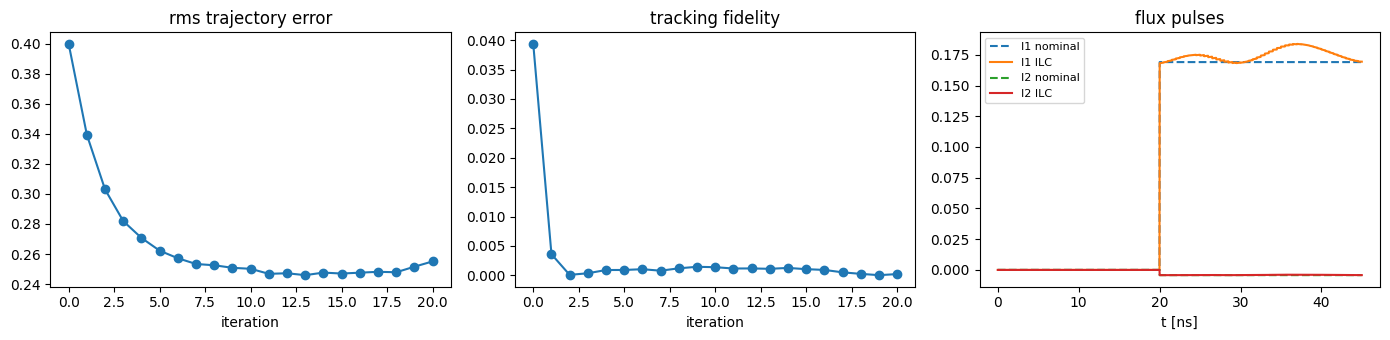

In [11]:
rng = np.random.default_rng(0)
N_ITER, GAIN, SUBSTEPS = 20, 0.7, 4
_, U_ref = ilc.simulate_rollout(ctrl)                             # nominal map to track

c_k, history = ctrl, []
for it in range(N_ITER + 1):
    y_true, U_hw = ilc.simulate_rollout(c_k, model=real_model, substeps=SUBSTEPS)   # noise-free, for scoring only
    history.append((np.sqrt(np.mean((y_true - y_nom) ** 2)), tracking_fidelity(model, U_hw, U_ref)))
    print(f"iter {it}: rms trajectory error {history[-1][0]:.4f}   tracking fidelity {history[-1][1]:.5f}")
    if it == N_ITER:
        break
    # "hardware" measurement: 4 times only, with shot noise
    y_meas, _ = ilc.simulate_rollout(c_k, model=real_model, substeps=SUBSTEPS,
                                     shots=SHOTS, rng=rng, times=meas_pos)
    c_k, e_filt, coeffs = ilc.update_pulse(c_k, y_meas, y_nom, V_r, U_r, Sigma_r,
                                           rows=meas_rows, gain=GAIN)

ctrl_ilc = c_k
h = np.array(history)
fig, ax = plt.subplots(1, 3, figsize=(14, 3.5))
ax[0].plot(h[:, 0], "o-"); ax[0].set_title("rms trajectory error"); ax[0].set_xlabel("iteration")
ax[1].plot(h[:, 1], "o-"); ax[1].set_title("tracking fidelity"); ax[1].set_xlabel("iteration")
for i, lab in enumerate(["I1", "I2"]):
    ax[2].plot(ctrl.t_mid, ctrl.I[i], "--", label=f"{lab} nominal")
    ax[2].plot(ctrl.t_mid, ctrl_ilc.I[i], label=f"{lab} ILC")
ax[2].set_title("flux pulses"); ax[2].set_xlabel("t [ns]"); ax[2].legend(fontsize=8)
plt.tight_layout()

## GRAPE hooks
* `model.slice_hamiltonians(ctrl)`: dense $H_k$ per slice, shape `(N, D, D)`
* `model.slice_propagators(ctrl)`: $U_k = e^{-iH_k\,dt}$
* `model.propagator(ctrl, "pwc" | "ode")`: total unitary
* `model.control_operators()`: $\partial H/\partial u$ for the z, x, y controls
* `model.detuning_jacobian(I)`: $\partial\Delta_i/\partial I_j$, the chain rule for optimizing in current space (it is zero at a sweet spot)
* `model.gate_fidelity(U, target)`: leakage-aware average gate fidelity on the computational subspace

The pack/unpack helpers below give a flat parameter vector for an external optimizer.

In [6]:
def pack(ctrl: Controls) -> np.ndarray:
    return np.concatenate([ctrl.I.ravel(), ctrl.ux.ravel(), ctrl.uy.ravel()])

def unpack(x: np.ndarray, n_slices: int, dt: float) -> Controls:
    I, ux, uy = np.split(np.asarray(x), 3)
    return Controls(dt, I.reshape(2, n_slices), ux.reshape(2, n_slices), uy.reshape(2, n_slices))

def infidelity(x, target, n_slices, dt):
    return 1 - model.gate_fidelity(model.propagator(unpack(x, n_slices, dt)), target)

# Example: score just the pi-pulse segment against X on qubit 1
X1 = qt.tensor(qt.sigmax(), qt.qeye(2)).full()
x_pi = pack(Controls(dt, ctrl.I[:, :N_pi], ctrl.ux[:, :N_pi], ctrl.uy[:, :N_pi]))
print("infidelity (pi pulse vs X1):", infidelity(x_pi, X1, N_pi, dt))

# Full sequence: magnitude of the computational-subspace block
U = model.propagator(ctrl, "pwc")
print("|U_sub| (rows/cols 00, 01, 10, 11):\n", np.round(np.abs(model.project_computational(U)), 3))

infidelity (pi pulse vs X1): 0.013113783030590853
|U_sub| (rows/cols 00, 01, 10, 11):
 [[0.113 0.025 0.993 0.   ]
 [0.993 0.005 0.113 0.025]
 [0.025 0.096 0.005 0.992]
 [0.001 0.986 0.025 0.097]]
